# 02 · Construindo grafos a partir de transações

**Objetivo:** transformar uma tabela de Pix em grafo, entender as decisões de modelagem envolvidas e usar as ferramentas do projeto para criar, recortar, desenhar e exportar grafos.

**Ferramentas:**

| Onde | O quê |
|---|---|
| `pixfraud.graph` | `build_graph`, `graph_from_edges`, `graph_from_csv`, `money_trail`, `adjacency_matrix`, `describe` |
| `pixfraud.visualization` | `draw_graph`, `save_graph` (PNG, HTML interativo, Gephi) |
| `pixfraud.patterns` | padrões de fraude prontos (notebook 04) |
| `scripts/02_exploracao/criar_grafo.py` | tudo isso pela linha de comando |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

from pixfraud.graph import build_graph, describe, money_trail
from pixfraud.simulation import generate_dataset, load_config, load_dataset, save_dataset
from pixfraud.visualization import draw_graph, save_graph

DADOS = Path("../data/synthetic")
if not (DADOS / "transactions.csv").exists():  # gera o dataset na primeira vez
    save_dataset(*generate_dataset(load_config("../configs/experimento.yaml")), DADOS)
contas, tx = load_dataset(DADOS)
tx.head()

,tx_id,timestamp,sender,receiver,amount,is_fraud,scenario
0,T0000000,2026-01-01 00:06:41,C001769,C001505,130.65,False,normal
1,T0000001,2026-01-01 00:11:48,C000547,C000323,9.17,False,normal
2,T0000002,2026-01-01 00:19:58,C001718,C000179,33.54,False,normal
3,T0000003,2026-01-01 00:20:49,C000717,C001361,29.84,False,normal
4,T0000004,2026-01-01 00:22:48,C001346,C000574,76.96,False,normal


## 1. Da tabela ao grafo: decisões de modelagem

Transformar transações em grafo envolve escolhas, e cada uma muda o resultado:

| Decisão | Opções | No projeto |
|---|---|---|
| O que é vértice | conta, CPF/CNPJ, chave Pix, dispositivo | conta |
| Sentido | direcionado ou não | direcionado (pagador → recebedor) |
| Pix repetidos | multigrafo ou agregado | agregado (`amount` = soma, `count` = nº de Pix) |
| Peso | valor total, nº de Pix, nenhum | depende da métrica |
| Janela de tempo | um dia, uma semana, o período todo | o período todo (30 dias) |

`build_graph` implementa as escolhas do projeto. Passar a lista de contas garante que contas sem nenhum Pix também virem vértices (isolados).

In [2]:
G = build_graph(tx, contas["account_id"])
describe(G)

vértices                               2142
arestas                               32446
direcionado                            True
multigrafo                            False
densidade                          0.007075
grau médio                        30.295051
laços                                     0
componentes fracamente conexas            1
componentes fortemente conexas          107
reciprocidade                      0.161253
acíclico (DAG)                        False
dtype: object

### Atributos nos vértices

Dá para anexar informações às contas, como o papel de cada uma. Aqui as vítimas ganham o papel `vitima` para aparecerem em verde nos desenhos. Lembre-se: o papel é um **rótulo**. Ele serve para avaliar e visualizar, nunca como entrada dos modelos.

In [3]:
info = contas.set_index("account_id")
papel = info["role"].where(~info["is_victim"], "vitima")
nx.set_node_attributes(G, papel.to_dict(), "role")
pd.Series(dict(G.nodes(data="role"))).value_counts()

normal           1832
vitima            168
comercio          100
laranja            24
intermediario      12
coletor             6
Name: count, dtype: int64

## 2. A janela de tempo muda o grafo

In [4]:
janelas = {"1 dia": "2026-01-02", "1 semana": "2026-01-08", "período todo": "2026-02-10"}
linhas = []
for nome, fim in janelas.items():
    H = build_graph(tx[tx["timestamp"] < fim])
    linhas.append({
        "janela": nome,
        "vértices": H.number_of_nodes(),
        "arestas": H.number_of_edges(),
        "densidade": round(nx.density(H), 5),
        "componentes fracas": nx.number_weakly_connected_components(H),
        "maior CFC": len(max(nx.strongly_connected_components(H), key=len)),
    })
pd.DataFrame(linhas)

,janela,vértices,arestas,densidade,componentes fracas,maior CFC
0,1 dia,1377,1347,0.00071,151,3
1,1 semana,2133,9146,0.00201,1,1663
2,período todo,2142,32446,0.00707,1,2036


Numa janela curta o grafo é fragmentado. Com o tempo, as comunidades se ligam numa grande componente. Uma quadrilha do dataset age em cerca de 2 dias: será que ela se destaca mais numa janela curta do que no mês inteiro? Calcular métricas em **janelas deslizantes** é uma boa ideia para a pesquisa.

## 3. Criando grafos do zero

Além de `graph_from_edges` (notebook 01), o NetworkX permite montar o grafo passo a passo e tem **geradores** de grafos clássicos:

In [5]:
H = nx.DiGraph()
H.add_node("loja", role="comercio")                         # vértice com atributo
H.add_edge("ana", "loja", amount=30.0)                      # aresta com atributo (cria "ana")
H.add_edges_from([("bia", "loja"), ("caio", "loja")], amount=10.0)
H.nodes["ana"]["role"] = "normal"                           # altera atributo de vértice
H["bia"]["loja"]["amount"] += 5                             # altera atributo de aresta
print(H.nodes(data=True))
print(H.edges(data=True))

[('loja', {'role': 'comercio'}), ('ana', {'role': 'normal'}), ('bia', {}), ('caio', {})]
[('ana', 'loja', {'amount': 30.0}), ('bia', 'loja', {'amount': 15.0}), ('caio', 'loja', {'amount': 10.0})]


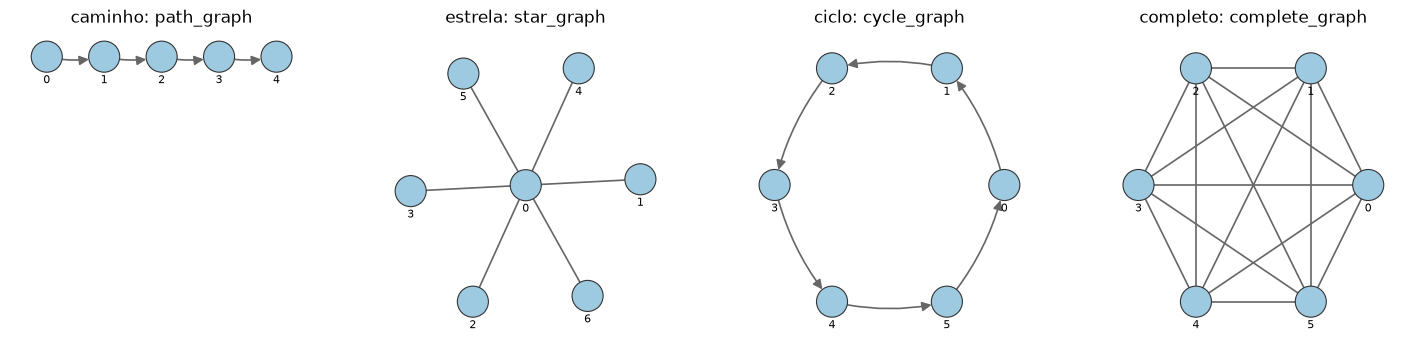

In [6]:
exemplos = {
    "caminho: path_graph": (nx.path_graph(5, create_using=nx.DiGraph), "flow"),
    "estrela: star_graph": (nx.star_graph(6), "spring"),
    "ciclo: cycle_graph": (nx.cycle_graph(6, create_using=nx.DiGraph), "circular"),
    "completo: complete_graph": (nx.complete_graph(6), "circular"),
}
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (nome, (H, layout)) in zip(axes, exemplos.items()):
    draw_graph(H, color_by=None, edge_labels=None, layout=layout, ax=ax, title=nome)

`draw_graph` aceita vários **layouts** (a disposição dos vértices no desenho):

- `"flow"`: da esquerda para a direita, no sentido do dinheiro (só para grafos acíclicos);
- `"spring"`: simulação física (arestas como molas);
- `"kamada_kawai"`: tenta fazer a distância no desenho refletir a distância no grafo;
- `"circular"` e `"shell"`: vértices em círculos.

O padrão `"auto"` usa `"flow"` quando o grafo é acíclico e `"kamada_kawai"` nos demais casos.

## 4. Recortes: vizinhança e trilha do dinheiro

Com milhares de vértices não dá para desenhar tudo. Duas formas de recortar em volta de uma conta:

- **ego graph** (`nx.ego_graph`): todas as contas a até $r$ saltos, em qualquer sentido;
- **trilha do dinheiro** (`money_trail`): segue o sentido das arestas, para frente (para onde o dinheiro foi) ou para trás (de onde veio).

Vamos pegar o coletor de uma quadrilha que usa lavagem em cadeia e seguir o dinheiro para trás:

C000333 | 37 contas na trilha


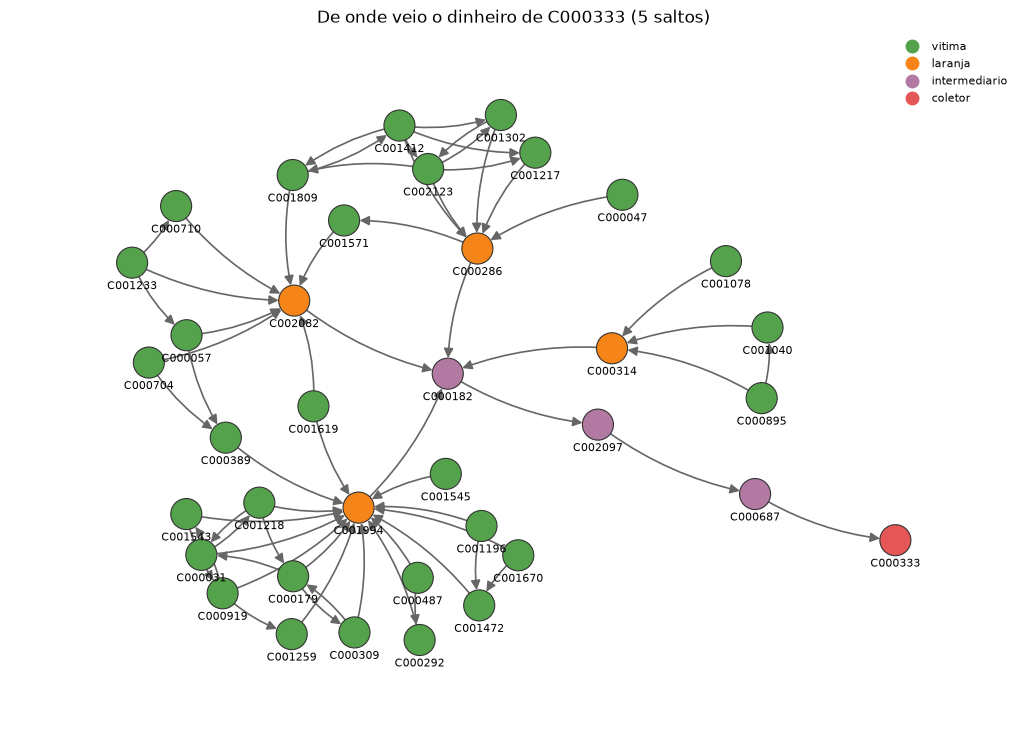

In [7]:
coletores = contas.loc[contas["role"] == "coletor", "account_id"]
coletor = next(c for c in coletores if any(G.nodes[p]["role"] == "intermediario" for p in G.predecessors(c)))
trilha = money_trail(G, coletor, max_hops=5, direction="backward")
print(coletor, "|", trilha.number_of_nodes(), "contas na trilha")

fig, ax = plt.subplots(figsize=(13, 9))
draw_graph(trilha, edge_labels=None, ax=ax, title=f"De onde veio o dinheiro de {coletor} (5 saltos)");

Seguindo o dinheiro para trás a partir do coletor aparecem, em ordem, os intermediários, as laranjas e as vítimas (em verde). Com mais um salto entrariam os contatos das vítimas, que não têm nada a ver com o golpe. **Escolher o alcance do recorte faz parte da análise.**

Compare com o *ego graph* de uma laranja, que mistura quem pagou e quem recebeu:

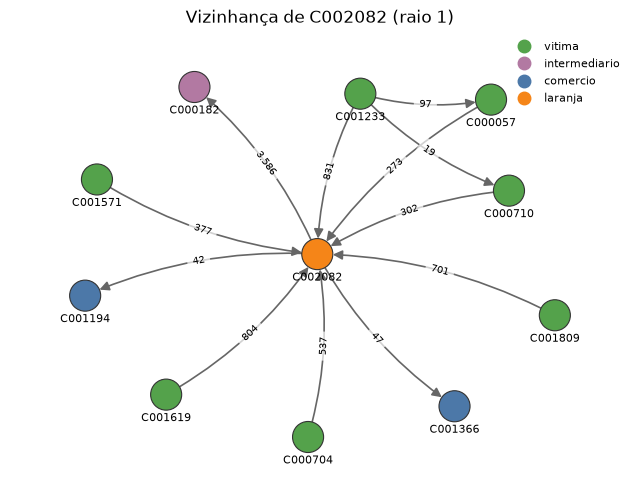

In [8]:
laranja = next(p for p in trilha if G.nodes[p]["role"] == "laranja")
ego = nx.ego_graph(G, laranja, radius=1, undirected=True)
draw_graph(ego, layout="kamada_kawai", title=f"Vizinhança de {laranja} (raio 1)");

## 5. Salvando e exportando

`save_graph` escolhe o formato pela extensão do arquivo:

- `.png`, `.svg`, `.pdf`: imagem para relatórios;
- `.html`: visualização **interativa**. Abra no navegador, arraste os vértices, dê zoom e passe o mouse sobre um vértice para ver papel, graus e valores;
- `.gexf`, `.graphml`: para o [Gephi](https://gephi.org), software livre de visualização de redes, bom para grafos grandes.

In [9]:
saida = Path("../reports/estudos")
print(save_graph(trilha, saida / "trilha_coletor.html", title=f"De onde veio o dinheiro de {coletor}"))
print(save_graph(trilha, saida / "trilha_coletor.png", edge_labels=None, title=f"Trilha de {coletor}"))
print(save_graph(G, "../data/processed/rede_completa.gexf"))  # grande: fica fora do git

..\reports\estudos\trilha_coletor.html


..\reports\estudos\trilha_coletor.png


..\data\processed\rede_completa.gexf


### Pela linha de comando

Os mesmos recortes podem ser feitos sem abrir o Python, com `scripts/02_exploracao/criar_grafo.py` (rode na raiz do repositório):

```bash
# trilha do dinheiro de uma conta do dataset
python scripts/02_exploracao/criar_grafo.py csv data/synthetic/transactions.csv --conta C000333 --saltos 5 --direcao tras --saida reports/estudos/trilha.html

# um padrão de fraude pronto
python scripts/02_exploracao/criar_grafo.py padrao mule_ring --saida reports/estudos/anel.png

# qualquer CSV com colunas de origem, destino e valor
python scripts/02_exploracao/criar_grafo.py csv meu_arquivo.csv --origem pagador --destino recebedor --valor valor --saida grafo.html
```

O script também imprime o resumo do grafo (`describe`).

## Exercícios

1. **Janela.** Monte o grafo só com o primeiro dia do dataset. Quantas componentes fracamente conexas ele tem? Qual é o tamanho da maior?
2. **Da vítima ao coletor.** Escolha uma vítima (`contas["is_victim"]`). Descubra para qual laranja ela pagou e quantos saltos a separam do coletor da quadrilha (`nx.shortest_path`).
3. **Multigrafo.** Monte o multigrafo do dataset (`graph_from_csv(..., aggregate=False)`) e encontre o par de contas com mais Pix entre si. Que papéis essas contas têm?
4. **Peso.** Liste as 10 arestas de maior valor (`amount`) do grafo agregado. Quantas envolvem contas fraudulentas? Isso sugere algum atributo novo?
5. **Exportar.** Salve em HTML a trilha **para frente** (2 saltos) de uma vítima e explore no navegador. Por que a trilha para frente de uma vítima fica tão maior que a trilha para trás de um coletor?

In [10]:
# seu código aqui